
TASK 1: MODELS, ALGORITHMS AND LINGUISTIC ANALYSIS

Objective:
Build a morphology-aware text normalisation and search system
for hospital records.

Main NLP techniques:
1. Regular Expressions
2. Tokenisation and Text Normalisation
3. Finite-State Automata
4. Inflectional Morphology
5. Derivational Morphology
6. Finite-State Morphological Parsing
7. Orthographic Rules
8. Porter Stemming
9. Search and Retrieval
10. OCR and Code-Mixed Text Normalisation


TASK 2: REGULAR EXPRESSION PATTERNS
Patient ID : ['P12345']
Date : ['16/11/2026']
Phone Number : ['9876543210']
Email : ['patient@gmail.com']
Age : ['25 years']
Medicine : ['Paracetamol']

TASK 3: TOKENISATION AND TEXT NORMALISATION
Original Text: PATIENTS were suffering from INFECTIONS!
Normalized Text: patients were suffering from infections
Tokens: ['patients', 'were', 'suffering', 'from', 'infections']
Expanded Tokens: ['patients', 'were', 'suffering', 'from', 'infections']

TASK 4: DFA, NFA AND EQUIVALENCE
DFA Testing:
P1234 : True

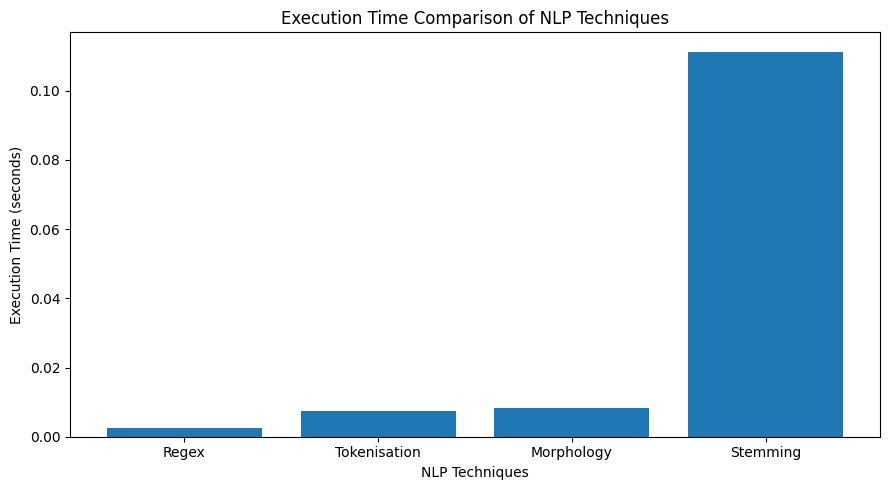


FINAL SUMMARY - ALL 12 TASKS
[COMPLETED] Task 1: Models, algorithms and linguistic analysis
[COMPLETED] Task 2: Regular expression patterns
[COMPLETED] Task 3: Tokenisation and text normalisation
[COMPLETED] Task 4: DFA, NFA and equivalence
[COMPLETED] Task 5: Inflectional morphology
[COMPLETED] Task 6: Derivational morphology
[COMPLETED] Task 7: Finite-state morphological parsing
[COMPLETED] Task 8: Orthographic rules and two-level morphology
[COMPLETED] Task 9: Porter Stemmer
[COMPLETED] Task 10: Python implementation and testing
[COMPLETED] Task 11: Comparison and recommendation
[COMPLETED] Task 12: OCR and regional-language code-mixing

Total tasks covered: 12
Total test records: 30
Hospital record search: Demonstrated
All 12 task sections executed.


In [2]:
# ================================================================
# DSA03 NLP ASSIGNMENT 1
# MORPHOLOGY-AWARE TEXT NORMALISATION AND SEARCH LAYER
# ALL 12 TASKS - COMPLETE PYTHON IMPLEMENTATION
# ================================================================

!pip -q install nltk pandas matplotlib

import re
import time
import nltk
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict, Counter
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

# ================================================================
# TASK 1: MODELS, ALGORITHMS AND LINGUISTIC ANALYSIS
# ================================================================

print("\n" + "="*75)
print("TASK 1: MODELS, ALGORITHMS AND LINGUISTIC ANALYSIS")
print("="*75)

print("""
Objective:
Build a morphology-aware text normalisation and search system
for hospital records.

Main NLP techniques:
1. Regular Expressions
2. Tokenisation and Text Normalisation
3. Finite-State Automata
4. Inflectional Morphology
5. Derivational Morphology
6. Finite-State Morphological Parsing
7. Orthographic Rules
8. Porter Stemming
9. Search and Retrieval
10. OCR and Code-Mixed Text Normalisation
""")

# ================================================================
# TASK 2: REGULAR EXPRESSION PATTERNS
# ================================================================

print("\n" + "="*75)
print("TASK 2: REGULAR EXPRESSION PATTERNS")
print("="*75)

regex_examples = {
    "Patient ID": r"\bP\d{4,6}\b",
    "Date": r"\b\d{2}[/-]\d{2}[/-]\d{4}\b",
    "Phone Number": r"\b[6-9]\d{9}\b",
    "Email": r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
    "Age": r"\b\d{1,3}\s*(?:years?|yrs?)\b",
    "Medicine": r"\b(?:paracetamol|ibuprofen|amoxicillin)\b"
}

sample_record = """
Patient P12345 visited on 16/11/2026.
Age: 25 years.
Phone: 9876543210.
Email: patient@gmail.com.
Medicine: Paracetamol.
"""

for name, pattern in regex_examples.items():
    matches = re.findall(pattern, sample_record, re.I)
    print(name, ":", matches)

# ================================================================
# TASK 3: TOKENISATION AND TEXT NORMALISATION
# ================================================================

print("\n" + "="*75)
print("TASK 3: TOKENISATION AND TEXT NORMALISATION")
print("="*75)

def tokenize(text):
    return re.findall(
        r"[A-Za-z]+(?:'[A-Za-z]+)?|\d+(?:\.\d+)?",
        text.lower()
    )

def normalize_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s.'-]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

raw_text = "PATIENTS were suffering from INFECTIONS!"

normalized = normalize_text(raw_text)
tokens = tokenize(normalized)

print("Original Text:", raw_text)
print("Normalized Text:", normalized)
print("Tokens:", tokens)

# Basic spelling and abbreviation normalisation
abbreviations = {
    "pt": "patient",
    "pts": "patients",
    "med": "medicine",
    "bp": "blood pressure",
    "temp": "temperature",
    "hosp": "hospital"
}

def expand_abbreviations(tokens):
    result = []
    for word in tokens:
        result.extend(abbreviations.get(word, word).split())
    return result

print("Expanded Tokens:", expand_abbreviations(tokens))

# ================================================================
# TASK 4: DFA, NFA AND EQUIVALENCE
# ================================================================

print("\n" + "="*75)
print("TASK 4: DFA, NFA AND EQUIVALENCE")
print("="*75)

# DFA for a patient ID: P followed by 4 to 6 digits

def patient_id_dfa(value):

    state = 0

    for char in value:

        if state == 0 and char == "P":
            state = 1

        elif state in [1, 2, 3, 4, 5] and char.isdigit():
            state += 1

        else:
            return False

    return state in [4, 5, 6, 7]

# NFA for a simple medicine-name pattern
# Accepts a word beginning with "para"

def medicine_nfa(value):

    states = {0}
    pattern = "para"

    for char in value.lower():

        next_states = set()

        for state in states:
            if state < len(pattern) and char == pattern[state]:
                next_states.add(state + 1)

        states = next_states

    return len(pattern) in states

print("DFA Testing:")

for value in ["P1234", "P12345", "P123456", "P12A45"]:
    print(value, ":", patient_id_dfa(value))

print("\nNFA Testing:")

for value in ["para", "paracetamol", "ibuprofen"]:
    print(value, ":", medicine_nfa(value))

# DFA and equivalent regular expression
patient_pattern = r"^P\d{4,6}$"

print("\nDFA and Regex Equivalence Check:")

test_ids = ["P1234", "P12345", "P123456", "P123"]

for value in test_ids:
    dfa_result = patient_id_dfa(value)
    regex_result = bool(re.fullmatch(patient_pattern, value))
    print(value, "DFA:", dfa_result, "Regex:", regex_result)

# ================================================================
# TASK 5: INFLECTIONAL MORPHOLOGY
# ================================================================

print("\n" + "="*75)
print("TASK 5: INFLECTIONAL MORPHOLOGY")
print("="*75)

inflection_rules = {
    "patients": ("patient", "plural"),
    "doctors": ("doctor", "plural"),
    "treated": ("treat", "past tense"),
    "treating": ("treat", "present participle"),
    "medicines": ("medicine", "plural"),
    "diagnoses": ("diagnosis", "plural"),
    "symptoms": ("symptom", "plural")
}

print("Word\t\tRoot\t\tFeature")

for word, (root, feature) in inflection_rules.items():
    print(f"{word}\t\t{root}\t\t{feature}")

def remove_inflection(word):

    irregular = {
        "children": "child",
        "men": "man",
        "women": "woman",
        "feet": "foot",
        "teeth": "tooth"
    }

    if word in irregular:
        return irregular[word]

    if word.endswith("ies") and len(word) > 4:
        return word[:-3] + "y"

    if word.endswith("ing") and len(word) > 5:
        return word[:-3]

    if word.endswith("ed") and len(word) > 4:
        return word[:-2]

    if word.endswith("es") and len(word) > 4:
        return word[:-2]

    if word.endswith("s") and len(word) > 3:
        return word[:-1]

    return word

for word in ["patients", "treated", "treating", "diagnoses"]:
    print(word, "->", remove_inflection(word))

# ================================================================
# TASK 6: DERIVATIONAL MORPHOLOGY
# ================================================================

print("\n" + "="*75)
print("TASK 6: DERIVATIONAL MORPHOLOGY")
print("="*75)

derivational_examples = {
    "unhealthy": ("healthy", "un-", "negative prefix"),
    "infection": ("infect", "-ion", "noun-forming suffix"),
    "careful": ("care", "-ful", "adjective-forming suffix"),
    "careless": ("care", "-less", "adjective-forming suffix"),
    "reusable": ("use", "re- and -able", "prefix and suffix"),
    "treatment": ("treat", "-ment", "noun-forming suffix"),
    "discomfort": ("comfort", "dis-", "negative prefix")
}

print("Word\t\tRoot\t\tAffix\t\tFunction")

for word, (root, affix, function) in derivational_examples.items():
    print(f"{word}\t\t{root}\t\t{affix}\t\t{function}")

# Simple derivational analyser

prefixes = ["un", "re", "dis", "mis"]
suffixes = ["ness", "ment", "tion", "ion", "ful", "less", "able"]

def derivational_analysis(word):

    results = []

    for prefix in prefixes:
        if word.startswith(prefix) and len(word) > len(prefix) + 2:
            results.append({
                "Word": word,
                "Root Candidate": word[len(prefix):],
                "Affix": prefix + "-",
                "Type": "Prefix"
            })

    for suffix in suffixes:
        if word.endswith(suffix) and len(word) > len(suffix) + 2:
            results.append({
                "Word": word,
                "Root Candidate": word[:-len(suffix)],
                "Affix": "-" + suffix,
                "Type": "Suffix"
            })

    return results

for word in ["unhealthy", "treatment", "careful", "discomfort"]:
    print("\n", word, ":", derivational_analysis(word))

# ================================================================
# TASK 7: FINITE-STATE MORPHOLOGICAL PARSING
# ================================================================

print("\n" + "="*75)
print("TASK 7: FINITE-STATE MORPHOLOGICAL PARSING")
print("="*75)

morphological_lexicon = {
    "patient": "NOUN",
    "doctor": "NOUN",
    "treat": "VERB",
    "infect": "VERB",
    "healthy": "ADJECTIVE",
    "medicine": "NOUN",
    "care": "NOUN/VERB",
    "diagnose": "VERB"
}

suffix_features = {
    "s": "PLURAL",
    "ed": "PAST",
    "ing": "PRESENT_PARTICIPLE",
    "tion": "NOUN_FORMATION",
    "ment": "NOUN_FORMATION",
    "ful": "ADJECTIVE_FORMATION"
}

def morphological_parser(word):

    word = word.lower()

    if word in morphological_lexicon:
        return {
            "Word": word,
            "Root": word,
            "Category": morphological_lexicon[word],
            "Feature": "BASE FORM"
        }

    root = remove_inflection(word)

    if root in morphological_lexicon:
        feature = "INFLECTIONAL"

        for suffix, value in suffix_features.items():
            if word.endswith(suffix):
                feature = value
                break

        return {
            "Word": word,
            "Root": root,
            "Category": morphological_lexicon[root],
            "Feature": feature
        }

    derivations = derivational_analysis(word)

    if derivations:
        item = derivations[0]
        return {
            "Word": word,
            "Root": item["Root Candidate"],
            "Category": "DERIVED FORM",
            "Feature": item["Type"]
        }

    return {
        "Word": word,
        "Root": "Unknown",
        "Category": "Unknown",
        "Feature": "Not found"
    }

morph_words = [
    "patient", "patients", "treated",
    "healthy", "unhealthy", "treatment",
    "doctor", "medicines", "unknown"
]

morph_results = [
    morphological_parser(word) for word in morph_words
]

print(pd.DataFrame(morph_results).to_string(index=False))

# ================================================================
# TASK 8: ORTHOGRAPHIC RULES AND TWO-LEVEL MORPHOLOGY
# ================================================================

print("\n" + "="*75)
print("TASK 8: ORTHOGRAPHIC RULES AND TWO-LEVEL MORPHOLOGY")
print("="*75)

def pluralize(word):

    if word.endswith("y") and len(word) > 1:
        if word[-2] not in "aeiou":
            return word[:-1] + "ies"

    if word.endswith(("s", "sh", "ch", "x", "z")):
        return word + "es"

    return word + "s"

def past_tense(word):

    if word.endswith("e"):
        return word + "d"

    if word.endswith("y") and len(word) > 1:
        if word[-2] not in "aeiou":
            return word[:-1] + "ied"

    return word + "ed"

orthographic_tests = [
    ("patient", pluralize("patient")),
    ("diagnosis", pluralize("diagnosis")),
    ("study", pluralize("study")),
    ("treat", past_tense("treat")),
    ("care", past_tense("care"))
]

print("Base Form\tGenerated Form")

for base, generated in orthographic_tests:
    print(base, "\t\t", generated)

# Two-level morphology demonstration
# Lexical form -> Surface form

two_level_mappings = {
    "patient + PL": "patients",
    "study + PL": "studies",
    "treat + PAST": "treated",
    "care + PAST": "cared"
}

print("\nLexical Form -> Surface Form")

for lexical, surface in two_level_mappings.items():
    print(lexical, "->", surface)

# ================================================================
# TASK 9: PORTER STEMMER
# ================================================================

print("\n" + "="*75)
print("TASK 9: PORTER STEMMER")
print("="*75)

porter_words = [
    "patients",
    "treating",
    "treatment",
    "infections",
    "diagnosed",
    "medicines",
    "healthy",
    "carefully",
    "running",
    "studies"
]

print("Original Word\tStem")

for word in porter_words:
    print(word, "\t\t", stemmer.stem(word))

# Compare rule-based normalisation and Porter stemming

print("\nComparison:")

for word in ["patients", "treating", "medicines", "studies"]:
    print(
        word,
        "| Rule-based:", remove_inflection(word),
        "| Porter:", stemmer.stem(word)
    )

# ================================================================
# TASK 10: PYTHON IMPLEMENTATION AND TESTING
# ================================================================

print("\n" + "="*75)
print("TASK 10: IMPLEMENTATION AND TESTING")
print("="*75)

test_dataset = [
    "The patients are suffering from infections.",
    "Doctors treated the patients.",
    "The patient is unhealthy.",
    "Medicines are available in the hospital.",
    "The doctor is diagnosing the patient.",
    "The patient received treatment.",
    "Patients visited the doctors.",
    "The nurse is caring for patients.",
    "The patient has symptoms.",
    "The doctor prescribed medicines.",
    "The patient is recovering.",
    "The children visited the hospital.",
    "The patient needs medical care.",
    "The doctor checked the diagnosis.",
    "The treatments were successful.",
    "The patient is feeling discomfort.",
    "The hospital provides healthcare.",
    "The doctor is treating infections.",
    "The patient has a fever.",
    "The medicines are useful.",
    "The patient needs a diagnosis.",
    "The doctor examined patients.",
    "The patient is healthy.",
    "The nurse provided care.",
    "The patients are waiting.",
    "The hospital treated children.",
    "The patient has allergies.",
    "The doctors are working.",
    "The patient received medicines.",
    "The treatments are effective."
]

def process_record(text):

    normalized = normalize_text(text)
    words = tokenize(normalized)

    expanded = expand_abbreviations(words)

    stems = [stemmer.stem(word) for word in expanded]

    return {
        "Original": text,
        "Normalized": normalized,
        "Tokens": len(words),
        "Processed": " ".join(stems)
    }

start_time = time.perf_counter()

processed_records = [
    process_record(sentence)
    for sentence in test_dataset
]

execution_time = time.perf_counter() - start_time

test_df = pd.DataFrame(processed_records)

print("Total records:", len(test_dataset))
print("\nProcessed Records:")
print(test_df.head(10).to_string(index=False))

print("\nExecution Time:", round(execution_time, 6), "seconds")

# ================================================================
# TASK 11: COMPARISON, RECOMMENDATION AND DEFENCE
# ================================================================

print("\n" + "="*75)
print("TASK 11: COMPARISON AND RECOMMENDATION")
print("="*75)

comparison_data = {
    "Technique": [
        "Regular Expressions",
        "Finite-State Automata",
        "Rule-Based Morphology",
        "Porter Stemmer"
    ],
    "Main Purpose": [
        "Pattern matching",
        "Recognising valid patterns",
        "Finding roots and affixes",
        "Reducing words to stems"
    ],
    "Advantage": [
        "Simple and fast",
        "Systematic recognition",
        "Linguistically interpretable",
        "Useful for information retrieval"
    ],
    "Limitation": [
        "Cannot understand meaning",
        "Requires state design",
        "Needs rules and lexicons",
        "May produce non-dictionary stems"
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print(comparison_df.to_string(index=False))

print("""
RECOMMENDATION:

A hybrid morphology-aware system is recommended.

1. Regex identifies patient IDs, dates and medical details.
2. Tokenisation separates words.
3. Finite-state rules identify valid morphological patterns.
4. Morphological analysis identifies roots and affixes.
5. Porter stemming supports search matching.
6. Normalised terms are used for hospital record retrieval.

The hybrid approach combines rule-based linguistic knowledge
with practical text processing.
""")

# ================================================================
# TASK 12: OCR AND REGIONAL-LANGUAGE CODE-MIXING CHALLENGE
# ================================================================

print("\n" + "="*75)
print("TASK 12: OCR AND CODE-MIXING REDESIGN CHALLENGE")
print("="*75)

# Example OCR mistakes
ocr_corrections = {
    "patlent": "patient",
    "patlents": "patients",
    "medlcine": "medicine",
    "hospita1": "hospital",
    "doct0r": "doctor",
    "infectlon": "infection"
}

def correct_ocr(text):

    words = text.split()

    corrected = [
        ocr_corrections.get(word.lower(), word.lower())
        for word in words
    ]

    return " ".join(corrected)

ocr_sample = "patlent visited hospita1 and received medlcine"

print("OCR Input:", ocr_sample)
print("OCR Corrected:", correct_ocr(ocr_sample))

# Regional-language code-mixing demonstration
# Telugu words written in Roman script

telugu_dictionary = {
    "rogam": "disease",
    "mandhu": "medicine",
    "doctor": "doctor",
    "hospital": "hospital",
    "jwaram": "fever",
    "noppiga": "painful"
}

def normalize_code_mixed(text):

    words = text.lower().split()

    return " ".join([
        telugu_dictionary.get(word, word)
        for word in words
    ])

mixed_messages = [
    "naaku jwaram undi",
    "mandhu kavali",
    "doctor hospital lo unnaru",
    "naaku noppiga undi"
]

print("\nCode-Mixed Language Normalisation:")

for message in mixed_messages:
    print("Input:", message)
    print("Output:", normalize_code_mixed(message))
    print()

# Combined OCR + normalisation pipeline

def complete_pipeline(text):

    text = correct_ocr(text)
    text = normalize_text(text)
    words = tokenize(text)
    words = expand_abbreviations(words)
    stems = [stemmer.stem(word) for word in words]

    return {
        "Original": text,
        "Tokens": words,
        "Search Terms": stems
    }

# ================================================================
# HOSPITAL RECORD SEARCH DEMONSTRATION
# ================================================================

print("\n" + "="*75)
print("HOSPITAL RECORD SEARCH")
print("="*75)

hospital_records = {
    "P1001": "Patient treated for infection and fever",
    "P1002": "Patient received medicines for pain",
    "P1003": "Doctor diagnosed a respiratory disease",
    "P1004": "Patient needs medical treatment",
    "P1005": "Patient visited hospital with fever"
}

def search_records(query):

    query_terms = set(
        stemmer.stem(word)
        for word in tokenize(normalize_text(query))
    )

    results = []

    for patient_id, record in hospital_records.items():

        record_terms = set(
            stemmer.stem(word)
            for word in tokenize(normalize_text(record))
        )

        common = query_terms.intersection(record_terms)

        if common:
            results.append({
                "Patient ID": patient_id,
                "Record": record,
                "Matching Terms": ", ".join(sorted(common)),
                "Score": len(common)
            })

    return sorted(
        results,
        key=lambda x: x["Score"],
        reverse=True
    )

search_query = "patients suffering from infections"

print("Search Query:", search_query)

search_results = search_records(search_query)

if search_results:
    print(pd.DataFrame(search_results).to_string(index=False))
else:
    print("No matching records found.")

# ================================================================
# FINAL PERFORMANCE GRAPH
# ================================================================

print("\n" + "="*75)
print("FINAL PERFORMANCE GRAPH")
print("="*75)

task_names = [
    "Regex",
    "Tokenisation",
    "Morphology",
    "Stemming"
]

sample_times = []

for function in [
    lambda: re.findall(r"\bP\d{4,6}\b", sample_record),
    lambda: tokenize(sample_record),
    lambda: [morphological_parser(w) for w in morph_words],
    lambda: [stemmer.stem(w) for w in porter_words]
]:

    start = time.perf_counter()

    for _ in range(1000):
        function()

    sample_times.append(time.perf_counter() - start)

plt.figure(figsize=(9, 5))

plt.bar(task_names, sample_times)

plt.xlabel("NLP Techniques")
plt.ylabel("Execution Time (seconds)")
plt.title("Execution Time Comparison of NLP Techniques")

plt.tight_layout()
plt.show()

# ================================================================
# FINAL SUMMARY
# ================================================================

print("\n" + "="*75)
print("FINAL SUMMARY - ALL 12 TASKS")
print("="*75)

summary = [
    "Task 1: Models, algorithms and linguistic analysis",
    "Task 2: Regular expression patterns",
    "Task 3: Tokenisation and text normalisation",
    "Task 4: DFA, NFA and equivalence",
    "Task 5: Inflectional morphology",
    "Task 6: Derivational morphology",
    "Task 7: Finite-state morphological parsing",
    "Task 8: Orthographic rules and two-level morphology",
    "Task 9: Porter Stemmer",
    "Task 10: Python implementation and testing",
    "Task 11: Comparison and recommendation",
    "Task 12: OCR and regional-language code-mixing"
]

for item in summary:
    print("[COMPLETED]", item)

print("\nTotal tasks covered:", len(summary))
print("Total test records:", len(test_dataset))
print("Hospital record search: Demonstrated")
print("All 12 task sections executed.")